### Summary of the Multi-Agent Reflective Research System

This agent is an **AI research assistant composed of multiple specialized agents** that work together to answer a user’s question with quality control and human supervision.

#### Workflow

1. **Planner Agent**

   * Breaks the user’s question into a structured research plan.

2. **Research Agent**

   * Converts the plan into a short search query.
   * Uses **web search (Tavily)** to gather information.
   * Generates a research summary using **Gemini**.

3. **Critic Agent**

   * Reviews the research.
   * Identifies missing information, errors, or improvements.

4. **Human-in-the-Loop**

   * The system pauses and asks a human to approve or reject the research.
   * If rejected → the research step runs again.

5. **Writer Agent**

   * Uses the research and critique to generate the **final refined answer**.

#### Key Features

* **Multi-agent architecture**
* **Self-reflection (critic agent)**
* **Human approval checkpoint**
* **Web search integration**
* **LangGraph workflow with loops**

#### In Simple Terms

It works like a **team of researchers**:

* One **plans the research**
* One **collects information**
* One **reviews the work**
* A **human approves it**
* One **writes the final report**.


In [ ]:
# Set the TAVILY_API_KEY for web search functionality.

In [ ]:
# Install necessary Python packages for LangChain, LangGraph, Google GenAI, and Tavily.
!pip -q install langchain langgraph langchain-groq tavily-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.0 MB/s eta 0:00:00


In [ ]:
# Load the GEMINI_API_KEY securely from Colab's user data.
from google.colab import userdata
import os
#GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
os.environ['GROQ_API_KEY'] = userdata.get("GROQ_API_KEY")

In [ ]:
# Import required libraries and define TypedDict for state management in LangGraph.
from typing import TypedDict
from langgraph.graph import StateGraph, END
#from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_groq import ChatGroq

from tavily import TavilyClient

In [ ]:
# Initialize the ChatGoogleGenerativeAI model with a specific model, API key, and temperature.
# llm = ChatGoogleGenerativeAI(
#     model="gemini-2.5-flash",
#     google_api_key=GEMINI_API_KEY,
#     temperature=0.2
# )

llm = ChatGroq(
    model="openai/gpt-oss-20b", # Specify the model to use from Groq
    temperature=0 # Set temperature to 0 for deterministic outputs
)

In [ ]:
# Initialize the TavilyClient for web searches and define a `web_search` function.
tavily = TavilyClient(api_key=TAVILY_API_KEY)

def web_search(query):

    # Tavily limit protection
    query = query[:350]

    results = tavily.search(
        query=query,
        max_results=5
    )

    return str(results)

In [ ]:
# Define the AgentState using TypedDict to represent the state of the research workflow.
class AgentState(TypedDict):

    question: str
    plan: str
    research: str
    critique: str
    approved: bool
    final_answer: str

In [ ]:
# Define the `planner_agent` function, responsible for breaking down a question into a research plan.
def planner_agent(state):

    question = state["question"]

    prompt = f"""
You are a research planner.

Break the following question into a research plan.

Question:
{question}

Return a clear step-by-step plan.
"""

    response = llm.invoke(prompt)

    return {"plan": response.content}

In [ ]:
# Define the `researcher_agent` function, which generates a search query, performs a web search, and summarizes the results.
def researcher_agent(state):

    plan = state["plan"]

    # Step 1: Generate short search query
    query_prompt = f"""
Convert the research plan below into a short web search query.

Plan:
{plan}

Return ONE search query under 15 words.
"""

    query = llm.invoke(query_prompt).content.strip()
    query = query[:350]

    # Step 2: Web search
    search_results = web_search(query)

    # Step 3: Generate research summary
    research_prompt = f"""
You are a research assistant.

Research Plan:
{plan}

Search Results:
{search_results}

Write a detailed research summary.
"""

    research = llm.invoke(research_prompt)

    return {"research": research.content}

In [ ]:
# Define the `critic_agent` function, responsible for evaluating the research and providing critique.
def critic_agent(state):

    research = state["research"]

    prompt = f"""
You are a research critic.

Evaluate the following research.

Research:
{research}

Identify:
- missing information
- logical errors
- possible improvements

Provide critique.
"""

    critique = llm.invoke(prompt)

    return {"critique": critique.content}

In [ ]:
# Define the `human_review` function, which allows a human to review the research and critique, deciding whether to approve.
def human_review(state):

    print("\n==============================")
    print("HUMAN REVIEW REQUIRED")
    print("==============================")

    print("\nResearch Summary:\n")
    print(state["research"])

    print("\nCritique:\n")
    print(state["critique"])

    decision = input("\nApprove research? (yes/no): ")

    if decision.lower() == "yes":
        return {"approved": True}
    else:
        return {"approved": False}

In [ ]:
# Define the `writer_agent` function, which uses the research and critique to produce a final, improved answer.
def writer_agent(state):

    research = state["research"]
    critique = state["critique"]

    prompt = f"""
You are an expert technical writer.

Research:
{research}

Critique:
{critique}

Improve the research and produce a final clear answer.
"""

    answer = llm.invoke(prompt)

    return {"final_answer": answer.content}

In [ ]:
# Define the `approval_router` function, which conditionally routes the workflow based on human approval.
def approval_router(state):

    if state["approved"]:
        return "writer"
    else:
        return "researcher"

In [ ]:
# Build and compile the LangGraph workflow, defining the nodes, entry point, and edges between agents.
workflow = StateGraph(AgentState)
 b
workflow.add_node("planner", planner_agent)
workflow.add_node("researcher", researcher_agent)
workflow.add_node("critic", critic_agent)
workflow.add_node("human_review", human_review)
workflow.add_node("writer", writer_agent)

workflow.set_entry_point("planner")

workflow.add_edge("planner", "researcher")
workflow.add_edge("researcher", "critic")
workflow.add_edge("critic", "human_review")

workflow.add_conditional_edges(
    "human_review",
    approval_router,
    {
        "writer": "writer",
        "researcher": "researcher"
    }
)

workflow.add_edge("writer", END)

app = workflow.compile()

In [ ]:
# Define the initial question and invoke the compiled LangGraph workflow to get the final answer.
question = "Impact of hydrogen fuel on future aviation"

result = app.invoke({
    "question": question,
    "plan": "",
    "research": "",
    "critique": "",
    "approved": False,
    "final_answer": ""
})

print("\n==============================")
print("FINAL ANSWER")
print("==============================\n")

print(result["final_answer"])


HUMAN REVIEW REQUIRED

Research Summary:

## Research Summary  
**Impact of Hydrogen Fuel on Future Aviation**  
*(Prepared for the interdisciplinary research team, 2026‑06‑11)*  

---

### 1. Executive Overview  

Hydrogen is emerging as a cornerstone of the aviation sector’s decarbonisation strategy.  Early‑stage concepts (e.g., Airbus ZERO‑AER, Boeing 787‑8 hydrogen) demonstrate that hydrogen can deliver **zero CO₂ emissions** during flight and, when produced from renewable electricity, can also reduce NOₓ, particulate matter, and other non‑CO₂ climate impacts.  However, the transition to hydrogen‑powered aircraft hinges on a complex interplay of **technology readiness, economics, infrastructure, policy, and stakeholder acceptance**.  

This research project is designed to provide a **holistic, evidence‑based assessment** of hydrogen’s potential to reshape aviation by 2035–2050.  The study will deliver actionable insights for manufacturers, airlines, regulators, and investors, and 

In [ ]:
print(app.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	planner(planner)
	researcher(researcher)
	critic(critic)
	human_review(human_review)
	writer(writer)
	__end__([<p>__end__</p>]):::last
	__start__ --> planner;
	critic --> human_review;
	human_review -.-> researcher;
	human_review -.-> writer;
	planner --> researcher;
	researcher --> critic;
	writer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



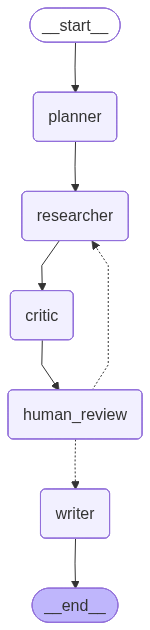

In [ ]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
# https://mermaid.live/edit#pako:eNp1U01vozAQ_SvW7CWRgIaPZsFUuWyue-up6xVyjQ1WwSBjmrZR_vsak0JaaU8zb-bNzBt_nIF1JQcMvu8TxTolZIWJQkg03YnVVBuHEGKjfuUYNVJxqoly9ErTvkaPx5woYopiMJZeFJs_D_1hQQ93_eHvFmMspB7MROwbqhTXm6vdTjHNB9uW1Ta8ui7DtDSSbWbjIvXYUlVo_ir5aXMLXPZkibbLbLazMK7KRZbzF1ENnTUtcpHvH9BVWb7Od-HbWfl3JcgPLGUV_x_CrCu_OQfX-lvdCl121pCv67nodZdZpV1kOHKBSi7o2BgkZNPgHyISOyG86dL8msuqNjgMoi8F7loc3e96yqR5x7svhOmIru2exfNeMKLAg0rLErDRI_eg5bqlE4Tz9FYImJq3nAC2bkn1CwGiLramp-qp69rPMt2NVQ1Y0GawaOxLavhRUvuo2iWq7Ypc_-pGZQDHaeSaAD7DG-AwS4Ik2cVpFsZJkoZR6sE74H0c_LTwPs6y-3QfZ-nFgw83Ngz2cZiEaZzGWRKFie3GS2k6_Xv-Au4nXP4B4OcOlQ
# If flowchart isnt printed above